In [23]:
# Step 1: Import libraries and load dataset

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the uploaded CSV automatically
csv_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "xjtu-2024-cycles.csv":
            csv_files.append(os.path.join(root, file))

if not csv_files:
    raise FileNotFoundError("xjtu-2024-cycles.csv not found in /kaggle/input")

CSV_PATH = csv_files[0]

# Load dataset
df = pd.read_csv(CSV_PATH)

print("Dataset loaded successfully!")
print("File:", CSV_PATH)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: /kaggle/input/datasets/singhbohdivydishu/battery-dataset01/xjtu-2024-cycles.csv
Shape: (27642, 13)


,batch,cell,cycle,label,charge_ah,discharge_ah,charge_ah_reported,discharge_ah_reported,coulombic_efficiency,v_max,v_min,duration_s,start_test_time_s
0,Batch-1,2C_battery-1,1,0.5C charge and 0.2C discharge [test capacity],1.28478,1.99128,1.285,1.991,1.54990,4.2000,2.5,25083.0,0.0
1,Batch-1,2C_battery-1,2,2C charge and 1C discharge,1.97587,1.86365,1.976,1.863,0.94320,4.1998,2.5,7108.5,25084.1
2,Batch-1,2C_battery-1,3,2C charge and 1C discharge,1.86633,1.87135,1.867,1.871,1.00269,4.1998,2.5,6978.1,32193.5
3,Batch-1,2C_battery-1,4,2C charge and 1C discharge,1.87307,1.87745,1.874,1.877,1.00234,4.1998,2.5,6966.2,39172.7
4,Batch-1,2C_battery-1,5,2C charge and 1C discharge,1.87882,1.88308,1.879,1.883,1.00227,4.1998,2.5,6963.5,46139.9


In [24]:
# Step 2: Dataset inspection

print("1. Dataset Information")
df.info()

print("\n2. Statistical Summary")
display(df.describe(include="all").T)

print("\n3. Missing Values")
missing = df.isnull().sum()
display(missing[missing > 0])

print("\n4. Unique Batches")
print(df["batch"].value_counts().sort_index())

print("\n5. Number of Unique Battery Cells")
print(df["cell"].nunique())

print("\n6. Records per Batch")
display(df.groupby("batch").agg(
    total_records=("cycle", "count"),
    unique_cells=("cell", "nunique"),
    min_cycle=("cycle", "min"),
    max_cycle=("cycle", "max")
))

1. Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27642 entries, 0 to 27641
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   batch                  27642 non-null  object 
 1   cell                   27642 non-null  object 
 2   cycle                  27642 non-null  int64  
 3   label                  27642 non-null  object 
 4   charge_ah              27642 non-null  float64
 5   discharge_ah           27642 non-null  float64
 6   charge_ah_reported     27642 non-null  float64
 7   discharge_ah_reported  27642 non-null  float64
 8   coulombic_efficiency   27642 non-null  float64
 9   v_max                  27642 non-null  float64
 10  v_min                  27642 non-null  float64
 11  duration_s             27642 non-null  float64
 12  start_test_time_s      27642 non-null  float64
dtypes: float64(9), int64(1), object(3)
memory usage: 2.7+ MB

2. Statistical Summary


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
batch,27642,6,Batch-6,8404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cell,27642,55,Sim_satellite_battery-5,1301,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cycle,27642.0,NaN,NaN,NaN,335.436365,265.949756,1.0,126.0,267.0,492.0,1301.0
label,27642,18,2.0C charge and 0.67C discharge,6943,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charge_ah,27642.0,NaN,NaN,NaN,1.700421,0.337427,0.07632,1.60034,1.822535,1.9112,2.02861
discharge_ah,27642.0,NaN,NaN,NaN,1.701585,0.337108,0.11152,1.6013,1.823435,1.91218,2.07664
charge_ah_reported,27642.0,NaN,NaN,NaN,1.701081,0.337397,0.076,1.601,1.823,1.912,2.029
discharge_ah_reported,27642.0,NaN,NaN,NaN,1.700329,0.336793,0.111,1.601,1.8215,1.911,2.077
coulombic_efficiency,27642.0,NaN,NaN,NaN,1.105214,1.195853,0.05569,0.98763,0.99997,1.00653,23.34148
v_max,27642.0,NaN,NaN,NaN,4.200085,0.002671,4.1995,4.2,4.2,4.2001,4.6397



3. Missing Values


Series([], dtype: int64)


4. Unique Batches
batch
Batch-1    3219
Batch-2    3742
Batch-3    4616
Batch-4    5678
Batch-5    1983
Batch-6    8404
Name: count, dtype: int64

5. Number of Unique Battery Cells
55

6. Records per Batch


,total_records,unique_cells,min_cycle,max_cycle
batch,,,,
Batch-1,3219,8,1,420
Batch-2,3742,15,1,322
Batch-3,4616,8,1,667
Batch-4,5678,8,1,799
Batch-5,1983,8,1,340
Batch-6,8404,8,1,1301


In [25]:
# Step 3: Analyse testing protocols

print("1. Number of records for each testing protocol:")
display(
    df.groupby(["batch", "label"])
      .size()
      .reset_index(name="records")
      .sort_values(["batch", "records"], ascending=[True, False])
)

print("\n2. Capacity-test records by batch:")

df["is_capacity_test"] = df["label"].str.contains(
    "test capacity", case=False, na=False
)

display(
    df.groupby("batch").agg(
        total_records=("cycle", "count"),
        capacity_test_records=("is_capacity_test", "sum"),
        unique_cells=("cell", "nunique")
    )
)

print("\n3. Example testing protocols:")
for batch in sorted(df["batch"].unique()):
    print(f"\n{batch}:")
    print(df.loc[df["batch"] == batch, "label"].value_counts())
    

1. Number of records for each testing protocol:


,batch,label,records
1,Batch-1,2C charge and 1C discharge,3211
0,Batch-1,0.5C charge and 0.2C discharge [test capacity],8
3,Batch-2,3C charge and 1C discharge,3727
2,Batch-2,0.5C charge and 0.2C discharge [test capacity],15
5,Batch-3,2C charge and 0.5C discharge,928
6,Batch-3,2C charge and 1C discharge,920
7,Batch-3,2C charge and 2C discharge,920
8,Batch-3,2C charge and 3C discharge,920
9,Batch-3,2C charge and 5C discharge,920
4,Batch-3,0.5C charge and 0.2C discharge [test capacity],8



2. Capacity-test records by batch:


,total_records,capacity_test_records,unique_cells
batch,,,
Batch-1,3219,8,8
Batch-2,3742,15,15
Batch-3,4616,8,8
Batch-4,5678,953,8
Batch-5,1983,173,8
Batch-6,8404,1461,8



3. Example testing protocols:

Batch-1:
label
2C charge and 1C discharge                        3211
0.5C charge and 0.2C discharge [test capacity]       8
Name: count, dtype: int64

Batch-2:
label
3C charge and 1C discharge                        3727
0.5C charge and 0.2C discharge [test capacity]      15
Name: count, dtype: int64

Batch-3:
label
2C charge and 0.5C discharge                      928
2C charge and 1C discharge                        920
2C charge and 3C discharge                        920
2C charge and 2C discharge                        920
2C charge and 5C discharge                        920
0.5C charge and 0.2C discharge [test capacity]      8
Name: count, dtype: int64

Batch-4:
label
2C charge and 0.5C discharge to 3V                945
2C charge and 1C discharge to 3V                  945
2C charge and 2C discharge to 3V                  945
2C charge and 5C discharge to 3V                  945
2C charge and 3C discharge to 3V                  945
2C charge and

In [26]:
# Step 4: Select comparable 1C discharge observations

conditions = (
    # Batch 1 and 2: regular 1C discharge
    (
        df["batch"].isin(["Batch-1", "Batch-2"])
        & df["label"].str.contains("1C discharge", case=False)
        & ~df["is_capacity_test"]
    )
    |
    # Batch 3: selected 1C discharge
    (
        (df["batch"] == "Batch-3")
        & (df["label"] == "2C charge and 1C discharge")
    )
    |
    # Batch 4 and 5: dedicated 1C capacity tests
    (
        df["batch"].isin(["Batch-4", "Batch-5"])
        & df["is_capacity_test"]
        & df["label"].str.contains("1C discharge", case=False)
    )
)

soh_df = df.loc[conditions].copy()

# Calculate State of Health
NOMINAL_CAPACITY = 2.0  # Ah

soh_df["SOH"] = (
    soh_df["discharge_ah"] / NOMINAL_CAPACITY
) * 100

print("Primary SOH dataset shape:", soh_df.shape)

print("\nRecords by batch:")
display(soh_df.groupby("batch").agg(
    records=("cycle", "count"),
    cells=("cell", "nunique")
))

print("\nSOH statistical summary:")
display(soh_df["SOH"].describe())

Primary SOH dataset shape: (8976, 15)

Records by batch:


,records,cells
batch,,
Batch-1,3211,8
Batch-2,3727,15
Batch-3,920,8
Batch-4,945,8
Batch-5,173,8



SOH statistical summary:


count    8976.000000
mean       93.301886
std         4.888298
min        74.211500
25%        90.958375
50%        94.773500
75%        97.261750
max        99.655500
Name: SOH, dtype: float64

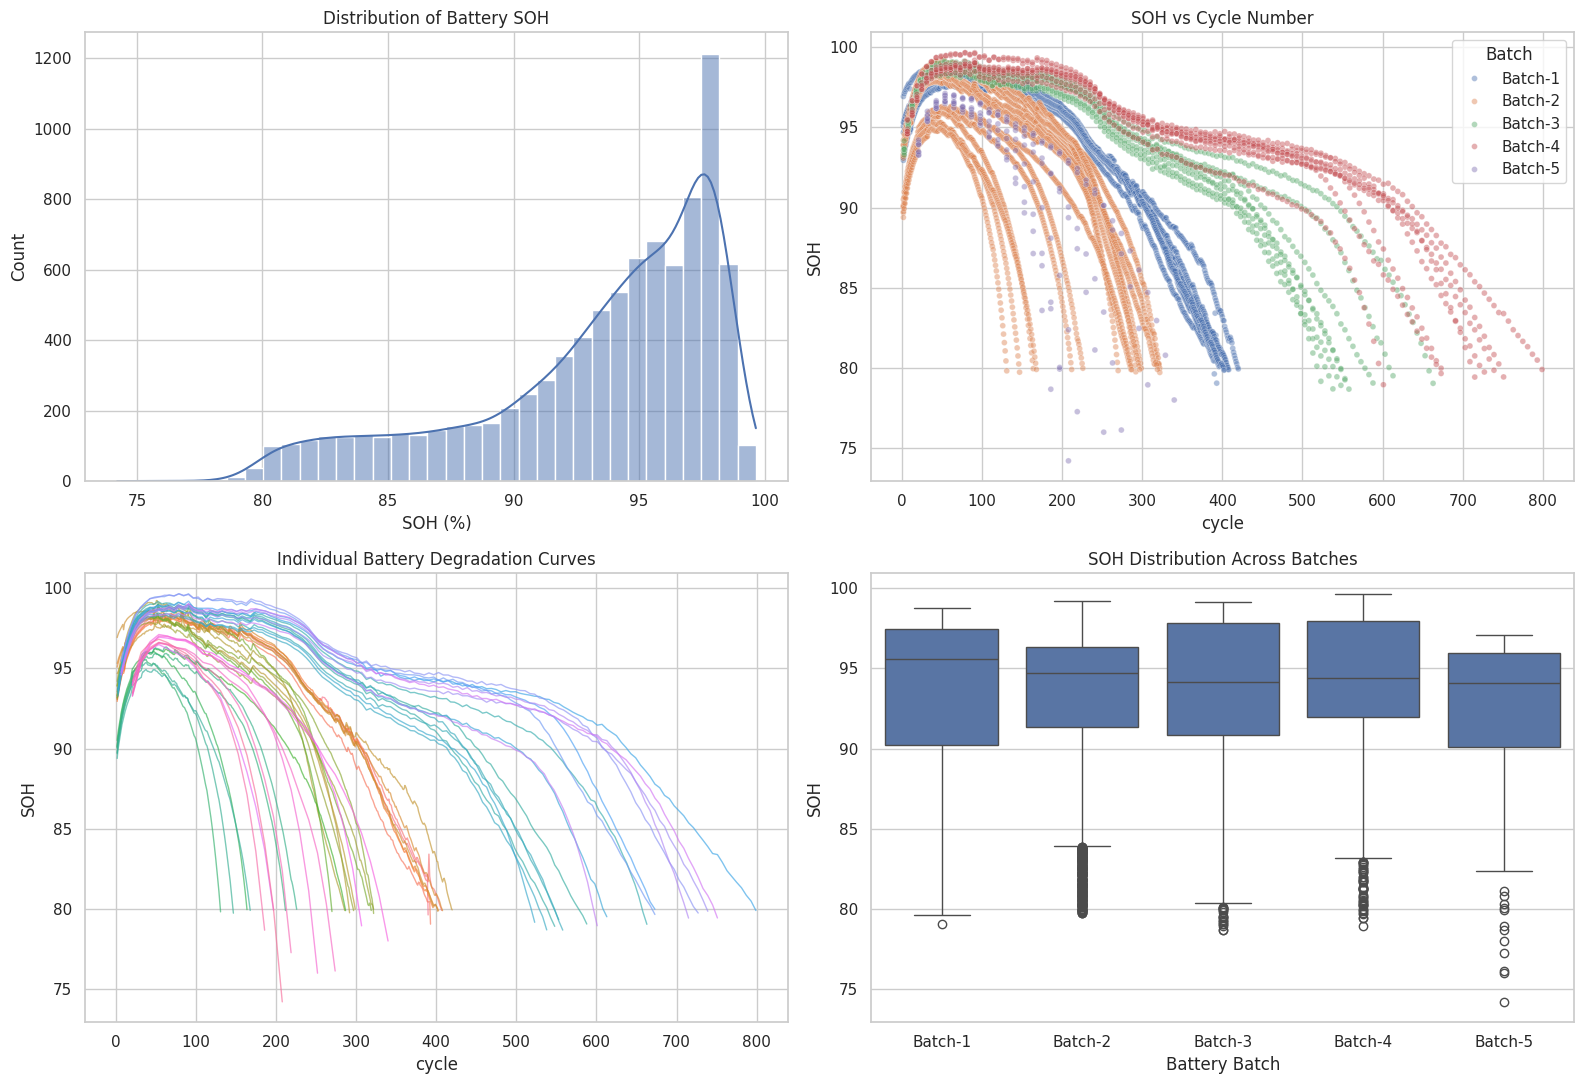

In [27]:
# Step 5: Exploratory Data Analysis

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. SOH distribution
sns.histplot(
    data=soh_df,
    x="SOH",
    bins=35,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Battery SOH")
axes[0, 0].set_xlabel("SOH (%)")

# 2. SOH vs cycle
sns.scatterplot(
    data=soh_df,
    x="cycle",
    y="SOH",
    hue="batch",
    alpha=0.45,
    s=18,
    ax=axes[0, 1]
)
axes[0, 1].set_title("SOH vs Cycle Number")
axes[0, 1].legend(title="Batch")

# 3. Individual battery degradation curves
sns.lineplot(
    data=soh_df,
    x="cycle",
    y="SOH",
    hue="cell",
    units="cell",
    estimator=None,
    alpha=0.65,
    linewidth=1,
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Individual Battery Degradation Curves")

# 4. Average SOH by batch
sns.boxplot(
    data=soh_df,
    x="batch",
    y="SOH",
    ax=axes[1, 1]
)
axes[1, 1].set_title("SOH Distribution Across Batches")
axes[1, 1].set_xlabel("Battery Batch")

plt.tight_layout()
plt.show()

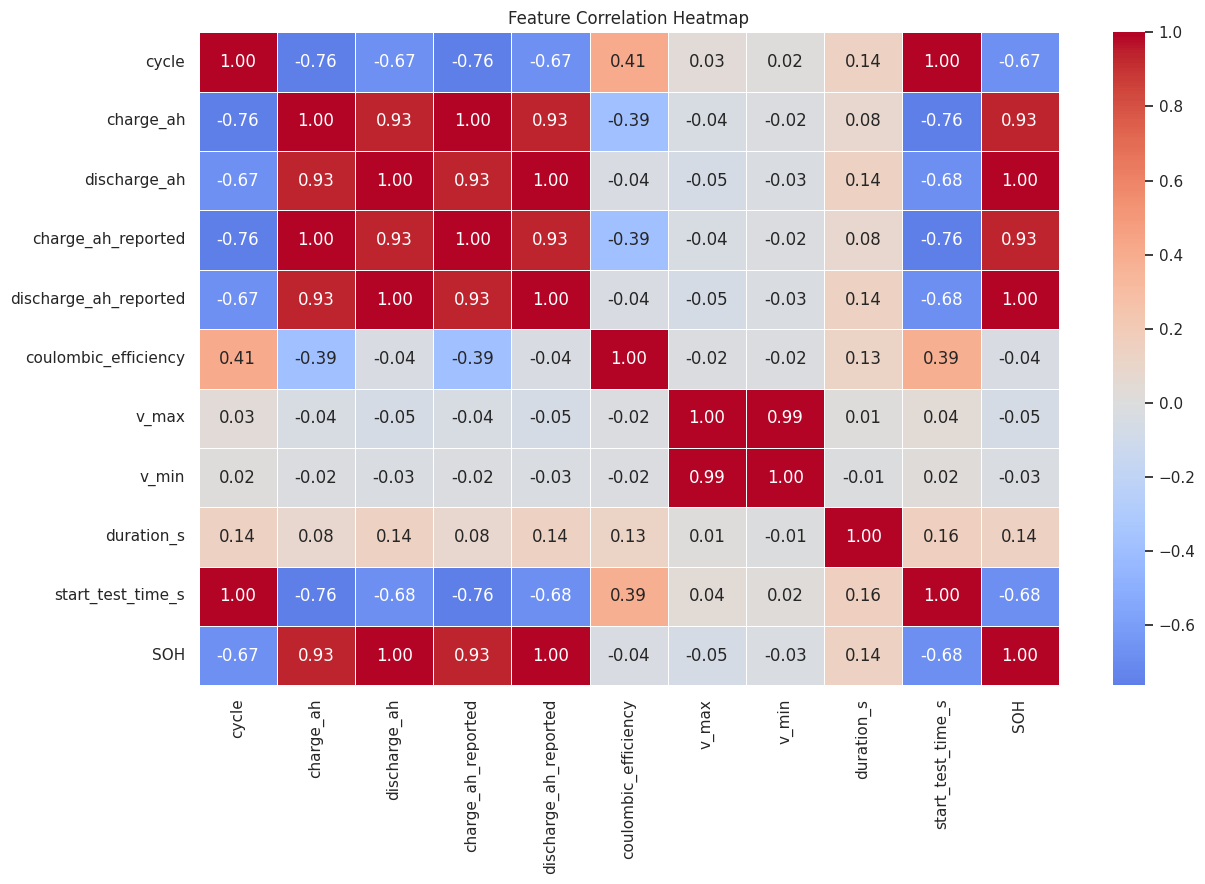

In [28]:
# Step 6: Correlation analysis

numeric_cols = [
    "cycle",
    "charge_ah",
    "discharge_ah",
    "charge_ah_reported",
    "discharge_ah_reported",
    "coulombic_efficiency",
    "v_max",
    "v_min",
    "duration_s",
    "start_test_time_s",
    "SOH"
]

corr_matrix = soh_df[numeric_cols].corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [30]:
# Step 8: Define features and target

features = [
    "cycle",
    "charge_ah",
    "charge_ah_reported",
    "v_max",
    "v_min",
    "duration_s"
]

target = "SOH"

X = soh_df[features].copy()
y = soh_df[target].copy()

print("Features:", features)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features: ['cycle', 'charge_ah', 'charge_ah_reported', 'v_max', 'v_min', 'duration_s']
Feature matrix shape: (8976, 6)
Target shape: (8976,)


,cycle,charge_ah,charge_ah_reported,v_max,v_min,duration_s
1,2,1.97587,1.976,4.1998,2.5,7108.5
2,3,1.86633,1.867,4.1998,2.5,6978.1
3,4,1.87307,1.874,4.1998,2.5,6966.2
4,5,1.87882,1.879,4.1998,2.5,6963.5
5,6,1.88434,1.885,4.1998,2.5,6962.6


1    93.1825
2    93.5675
3    93.8725
4    94.1540
5    94.4055
Name: SOH, dtype: float64

In [31]:
# Step 9: Battery-wise train-test split

from sklearn.model_selection import GroupShuffleSplit

groups = soh_df["cell"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("\nTraining cells:", soh_df.iloc[train_idx]["cell"].nunique())
print("Testing cells:", soh_df.iloc[test_idx]["cell"].nunique())

print("\nOverlapping cells:",
      set(soh_df.iloc[train_idx]["cell"]) &
      set(soh_df.iloc[test_idx]["cell"]))

Training samples: (7402, 6)
Testing samples: (1574, 6)

Training cells: 37
Testing cells: 10

Overlapping cells: set()


In [32]:
# Step 10: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nTraining feature means:")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nTraining feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 3))

Scaled training shape: (7402, 6)
Scaled testing shape: (1574, 6)

Training feature means:
[ 0.  0. -0. -0.  0.  0.]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1.]


In [33]:
# Step 11: Linear Regression and SVR

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "SVR": SVR(kernel="rbf", C=100, gamma="scale", epsilon=0.1)
}

results = []
trained_models = {}

# Train and evaluate
for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

# Display results
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.4484,1.9943,0.8355
1,SVR,0.7214,1.7514,0.8731


In [34]:
# Step 12: XGBoost Regression

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
xgb_pred = xgb_model.predict(X_test)

# Evaluate
xgb_results = {
    "Model": "XGBoost",
    "MAE": mean_absolute_error(y_test, xgb_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, xgb_pred)),
    "R2 Score": r2_score(y_test, xgb_pred)
}

results.append(xgb_results)
trained_models["XGBoost"] = xgb_model

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.4484,1.9943,0.8355
1,SVR,0.7214,1.7514,0.8731
2,XGBoost,0.5682,1.3356,0.9262


In [43]:
# Step 13: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Evaluate
rf_results = {
    "Model": "Random Forest",
    "MAE": mean_absolute_error(y_test, rf_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, rf_pred)),
    "R2 Score": r2_score(y_test, rf_pred)
}

trained_models["Random Forest"] = rf_model

# Update final comparison
final_results = pd.concat(
    [final_results, pd.DataFrame([rf_results])],
    ignore_index=True
)

display(final_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.4484,1.9943,0.8355
1,SVR,0.7214,1.7514,0.8731
2,XGBoost,0.5682,1.3356,0.9262
3,Random Forest,0.4534,1.1595,0.9444


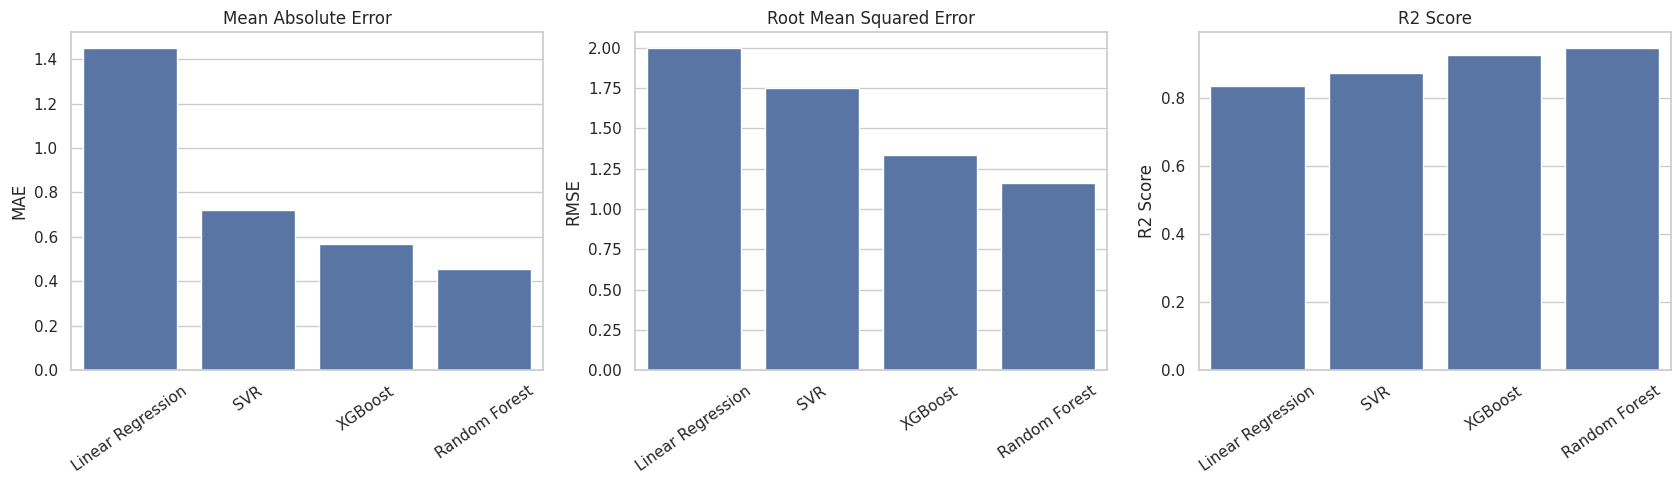

In [44]:
# Step 14: Model comparison charts

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["MAE", "RMSE", "R2 Score"]
titles = ["Mean Absolute Error", "Root Mean Squared Error", "R2 Score"]

for ax, metric, title in zip(axes, metrics, titles):

    sns.barplot(
        data=final_results,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


,Feature,Importance
1,charge_ah,0.409366
2,charge_ah_reported,0.314393
0,cycle,0.188025
5,duration_s,0.059060
3,v_max,0.028590
4,v_min,0.000567


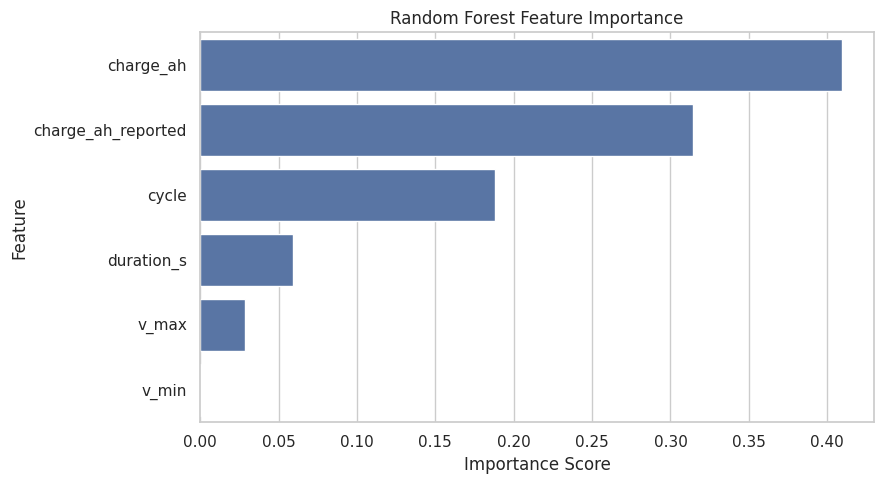

In [45]:
# Step 15: Random Forest Feature Importance

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

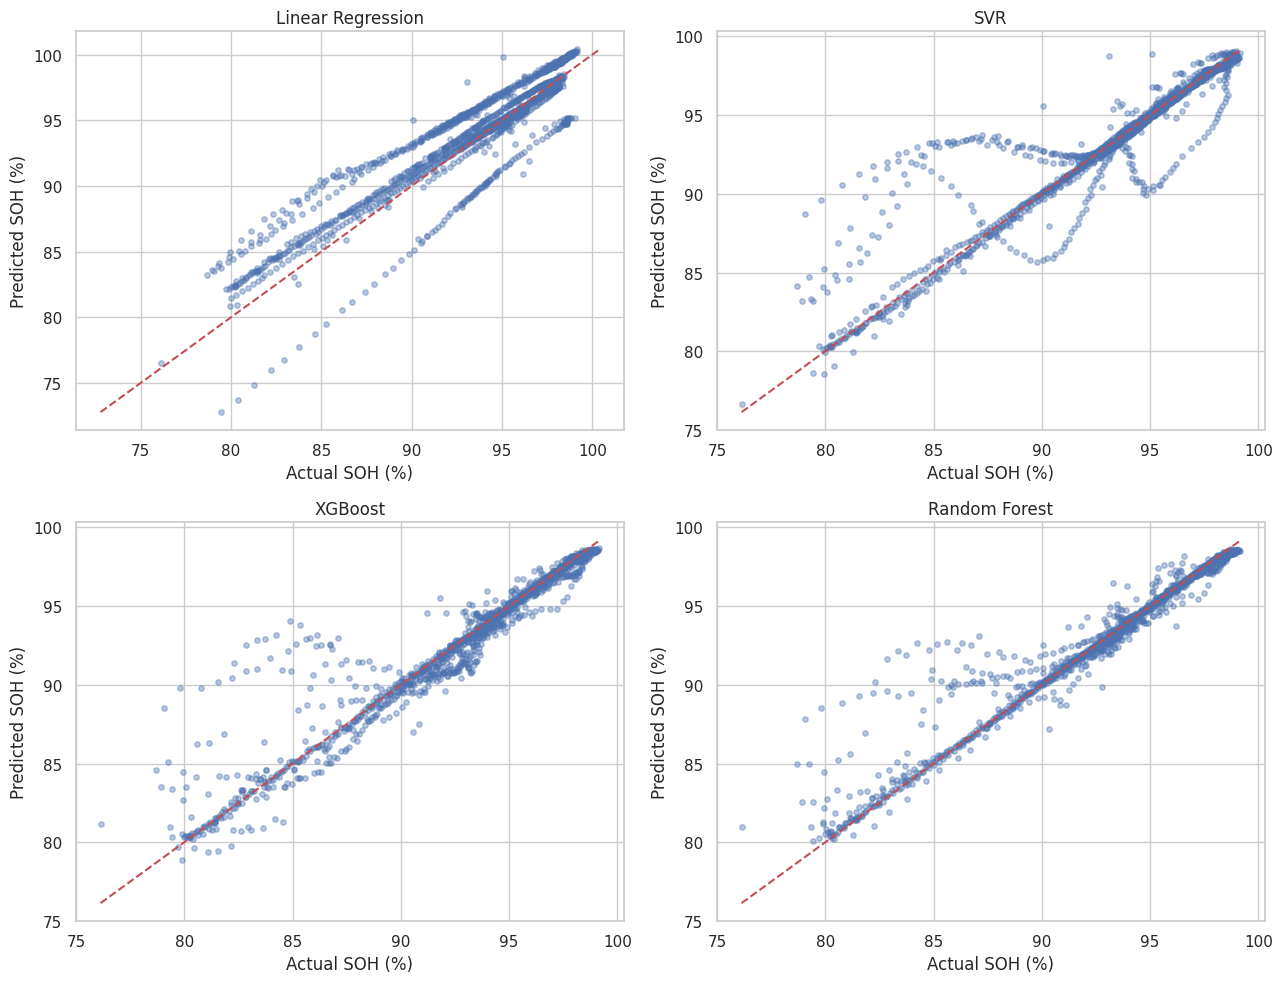

In [46]:
# Step 16: Actual vs Predicted SOH

predictions = {
    "Linear Regression": trained_models["Linear Regression"].predict(X_test_scaled),
    "SVR": trained_models["SVR"].predict(X_test_scaled),
    "XGBoost": trained_models["XGBoost"].predict(X_test),
    "Random Forest": trained_models["Random Forest"].predict(X_test)
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, pred) in zip(axes.flat, predictions.items()):

    ax.scatter(y_test, pred, alpha=0.4, s=15)

    lower = min(y_test.min(), pred.min())
    upper = max(y_test.max(), pred.max())

    ax.plot([lower, upper], [lower, upper], "r--")

    ax.set_title(name)
    ax.set_xlabel("Actual SOH (%)")
    ax.set_ylabel("Predicted SOH (%)")

plt.tight_layout()
plt.show()

In [47]:
# Step 17: Final model ranking

final_results = final_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

final_results.insert(
    0,
    "Rank",
    range(1, len(final_results) + 1)
)

display(final_results.round(4))

print("\nBest Model:", final_results.iloc[0]["Model"])
print("Best MAE:", final_results.iloc[0]["MAE"])
print("Best RMSE:", final_results.iloc[0]["RMSE"])
print("Best R2:", final_results.iloc[0]["R2 Score"])

,Rank,Model,MAE,RMSE,R2 Score
0,1,Random Forest,0.4534,1.1595,0.9444
1,2,XGBoost,0.5682,1.3356,0.9262
2,3,SVR,0.7214,1.7514,0.8731
3,4,Linear Regression,1.4484,1.9943,0.8355



Best Model: Random Forest
Best MAE: 0.45341355687768786
Best RMSE: 1.1594559495263879
Best R2: 0.9443948166878678


In [50]:
# Step 18: Save trained Random Forest model

import os
import joblib

# Create model directory
os.makedirs("/kaggle/working/model", exist_ok=True)

# Prepare model bundle
model_bundle = {
    "model": rf_model,
    "features": features,
    "model_name": "Random Forest Regressor",
    "target": "SOH",
    "nominal_capacity_ah": 2.0,
    "metrics": {
        "MAE": 0.4534,
        "RMSE": 1.1595,
        "R2": 0.9444
    }
}

# Save model
MODEL_PATH = "/kaggle/working/model/soh_prediction_model.pkl"

joblib.dump(model_bundle, MODEL_PATH)

# Verify file
if os.path.exists(MODEL_PATH):
    print("Model saved successfully!")
    print("Path:", MODEL_PATH)
    print("File size:", round(os.path.getsize(MODEL_PATH) / 1024, 2), "KB")
else:
    print("Model saving failed!")

Model saved successfully!
Path: /kaggle/working/model/soh_prediction_model.pkl
File size: 54256.51 KB


In [51]:

# Step 20: Save all models, metrics and visualisations

import os
import json
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Create project output directories
# --------------------------------------------------

OUTPUT_DIR = "/kaggle/working/battery_health_project"

MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

# --------------------------------------------------
# 2. Save individual trained models
# --------------------------------------------------

model_files = {
    "Linear Regression": "linear_regression.pkl",
    "SVR": "svr.pkl",
    "XGBoost": "xgboost.pkl",
    "Random Forest": "random_forest.pkl"
}

for name, filename in model_files.items():

    joblib.dump(
        trained_models[name],
        os.path.join(MODEL_DIR, filename)
    )

    print(f"Saved: {filename}")

# Save combined model bundle
all_models_bundle = {
    "models": trained_models,
    "features": features,
    "target": "SOH",
    "best_model": "Random Forest",
    "nominal_capacity_ah": 2.0
}

joblib.dump(
    all_models_bundle,
    os.path.join(MODEL_DIR, "all_models_bundle.pkl")
)

# --------------------------------------------------
# 3. Save model evaluation results
# --------------------------------------------------

final_results.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

print("\nModel comparison CSV saved.")

# --------------------------------------------------
# 4. Generate predictions for all four models
# --------------------------------------------------

predictions = {
    "Linear Regression": trained_models["Linear Regression"].predict(
        X_test_scaled
    ),
    "SVR": trained_models["SVR"].predict(
        X_test_scaled
    ),
    "XGBoost": trained_models["XGBoost"].predict(
        X_test
    ),
    "Random Forest": trained_models["Random Forest"].predict(
        X_test
    )
}

# --------------------------------------------------
# 5. Save model comparison chart
# --------------------------------------------------

metrics = ["MAE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=final_results,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# --------------------------------------------------
# 6. Save actual vs predicted plots
# --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, pred) in zip(
    axes.flat, predictions.items()
):

    ax.scatter(
        y_test,
        pred,
        alpha=0.4,
        s=15
    )

    lower = min(y_test.min(), pred.min())
    upper = max(y_test.max(), pred.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual SOH (%)")
    ax.set_ylabel("Predicted SOH (%)")

plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "actual_vs_predicted.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# --------------------------------------------------
# 7. Save individual model prediction plots
# --------------------------------------------------

for name, pred in predictions.items():

    plt.figure(figsize=(7, 6))

    plt.scatter(y_test, pred, alpha=0.5, s=18)

    lower = min(y_test.min(), pred.min())
    upper = max(y_test.max(), pred.max())

    plt.plot([lower, upper], [lower, upper], "r--")

    plt.title(f"{name}: Actual vs Predicted SOH")
    plt.xlabel("Actual SOH (%)")
    plt.ylabel("Predicted SOH (%)")

    plt.tight_layout()

    filename = name.lower().replace(" ", "_") + "_prediction.png"

    plt.savefig(
        os.path.join(PLOT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

# --------------------------------------------------
# 8. Save Random Forest feature importance
# --------------------------------------------------

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": trained_models["Random Forest"].feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "feature_importance.csv"),
    index=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# --------------------------------------------------
# 9. Save model metadata
# --------------------------------------------------

metadata = {
    "project": "EV Battery Health Prediction Using Machine Learning",
    "dataset": "XJTU-2024",
    "target": "SOH",
    "nominal_capacity_ah": 2.0,
    "features": features,
    "models": list(model_files.keys()),
    "best_model": "Random Forest",
    "evaluation_metrics": final_results.to_dict(orient="records")
}

with open(
    os.path.join(OUTPUT_DIR, "metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

# --------------------------------------------------
# 10. Display saved files
# --------------------------------------------------

print("\n========== EXPORT COMPLETED ==========")

for root, dirs, files in os.walk(OUTPUT_DIR):

    for filename in files:

        filepath = os.path.join(root, filename)

        size_kb = os.path.getsize(filepath) / 1024

        print(f"{filename:<35} {size_kb:.2f} KB")

print("\nAll models and visualisations saved successfully!")
print("Output directory:", OUTPUT_DIR)


Saved: linear_regression.pkl
Saved: svr.pkl
Saved: xgboost.pkl
Saved: random_forest.pkl

Model comparison CSV saved.

========== EXPORT COMPLETED ==========
feature_importance.csv              0.20 KB
metadata.json                       1.25 KB
model_comparison.csv                0.30 KB
random_forest.pkl                   54256.28 KB
linear_regression.pkl               0.63 KB
all_models_bundle.pkl               55899.33 KB
xgboost.pkl                         1240.51 KB
svr.pkl                             270.79 KB
xgboost_prediction.png              357.14 KB
linear_regression_prediction.png    384.10 KB
actual_vs_predicted.png             1080.84 KB
svr_prediction.png                  352.67 KB
feature_importance.png              86.62 KB
random_forest_prediction.png        326.29 KB
model_comparison.png                174.54 KB

All models and visualisations saved successfully!
Output directory: /kaggle/working/battery_health_project


In [52]:
# Step 21: Create ZIP archive of complete project

import os
import shutil
from IPython.display import FileLink, display

PROJECT_DIR = "/kaggle/working/battery_health_project"
ZIP_PATH = "/kaggle/working/battery_health_project.zip"

# Verify project directory
if not os.path.exists(PROJECT_DIR):
    raise FileNotFoundError("Project directory not found!")

# Create ZIP archive
shutil.make_archive(
    ZIP_PATH.replace(".zip", ""),
    "zip",
    root_dir="/kaggle/working",
    base_dir="battery_health_project"
)

# Verify archive
print("ZIP created successfully!")
print("File size:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2), "MB")

# Display download link
display(FileLink(ZIP_PATH))

ZIP created successfully!
File size: 33.75 MB


/kaggle/working/battery_health_project.zip